# Supplementary Figure 3

Distinct hippocampal representations of competing scenes predict multiple measures of memory-guided eye movements. Accompanies Figure 3. Reads `dataframes/pattern_sim_behav_data.csv` and `dataframes/pattern_sim_avg.csv`, produced by `figure3.ipynb` -- run that notebook first.

In [1]:
import os.path as op

import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib.pyplot as plt

from mgvs_release import config
from mgvs_release.plotting import setup_style, plot_rank_bin_effect, push_to_back, save_fig
from mgvs_release.stats import paired_ttest

In [2]:
setup_style()

In [3]:
deriv_dir = config.DERIV_DIR
model = 'default'

save_dir = '../plots/'
dataframes_dir = '../dataframes/'

## Load previously computed dataframes

In [4]:
ps_diff_perf_sorted = pd.read_csv(op.join(dataframes_dir, 'pattern_sim_behav_data.csv'),
                                   index_col=0, float_precision='round_trip')
ps_diff_mean = pd.read_csv(op.join(dataframes_dir, 'pattern_sim_avg.csv'),
                            index_col=0, float_precision='round_trip')

## Supplementary Fig. 3A: HIPP pattern similarity vs. search error, uncentered

In [5]:
ps_diff_perf_sorted_hipp = ps_diff_perf_sorted.query("roi=='hipp' & sacc_type=='first'")
ps_diff_perf_sorted_hipp = ps_diff_perf_sorted_hipp.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

/tmp/ipykernel_1533743/3885230567.py:3: UserWarning: 
The palette list has fewer values (1) than needed (32) and will cycle, which may produce an uninterpretable plot.
  sns.stripplot(x='rank_bin', y='next_sacc_targ_err', ax=ax, hue='subj', palette=['#9970ab'],
/tmp/ipykernel_1533743/3885230567.py:12: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set(ylabel='Search error ($\degree$)\n', ylim=[20, 100],


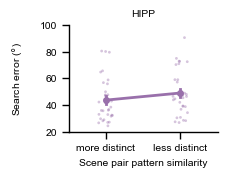

In [6]:
f, ax = plt.subplots(1, 1, figsize=(2.3, 1.8))

sns.stripplot(x='rank_bin', y='next_sacc_targ_err', ax=ax, hue='subj', palette=['#9970ab'],
              alpha=.4, s=2, data=ps_diff_perf_sorted_hipp)

push_to_back(ax)

sns.pointplot(x='rank_bin', y='next_sacc_targ_err', errorbar=('se'), ax=ax,
              color='#9970ab', markersize=3.5, linewidth=2,
              data=ps_diff_perf_sorted_hipp)
ax.legend_ = None
ax.set(ylabel='Search error ($\degree$)\n', ylim=[20, 100],
       xlabel='Scene pair pattern similarity', xticklabels=['more distinct', 'less distinct'], title='HIPP')
sns.despine()
f.tight_layout()
save_fig(f, op.join(save_dir, 'sfig3a'))

## Supplementary Fig. 3B: Robust to binarized search accuracy

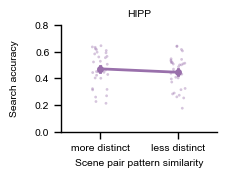

In [7]:
plot_rank_bin_effect(ps_diff_perf_sorted_hipp, y='next_targ_resp', color='#9970ab', title='HIPP',
                      ylabel='Search accuracy\n', ylim=[0, .8],
                      save_path=op.join(save_dir, 'sfig3b.svg'))

In [8]:
# Higher search accuracy for more distinct (lower pattern similarity) pairs vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_hipp.query("rank_bin==1")['next_targ_resp'],
             ps_diff_perf_sorted_hipp.query("rank_bin==2")['next_targ_resp'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,2.04266,31,two-sided,0.049669,"[0.0, 0.05]",0.205831,1.173,0.203862


## Supplementary Fig. 3C: Robust to last saccade instead of first

In [9]:
ps_diff_perf_sorted_hipp_last = ps_diff_perf_sorted.query("roi=='hipp' & sacc_type=='last'")
ps_diff_perf_sorted_hipp_last = ps_diff_perf_sorted_hipp_last.groupby(
    ['subj', 'rank_bin']).mean(numeric_only=True).reset_index()

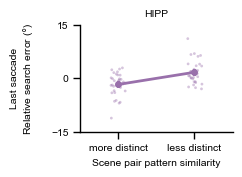

In [10]:
plot_rank_bin_effect(ps_diff_perf_sorted_hipp_last, y='next_targ_err_center', color='#9970ab', title='HIPP',
                      ylabel='Last saccade\nRelative search error ($\degree$)\n',
                      ylim=[-15, 15], yticks=[-15, 0, 15],
                      figsize=(2.45, 1.8), save_path=op.join(save_dir, 'sfig3c.svg'))

In [11]:
# Smaller saccade errors (last saccade) for more distinct (lower pattern
# similarity) pairs vs less distinct pairs
paired_ttest(ps_diff_perf_sorted_hipp_last.query("rank_bin==1")['next_sacc_targ_err'],
             ps_diff_perf_sorted_hipp_last.query("rank_bin==2")['next_sacc_targ_err'])

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power
T-test,-3.008072,31,two-sided,0.005182,"[-5.73, -1.1]",0.225094,7.732,0.234654


## Supplementary Fig. 3D: Robust to continuous (unbinned) pattern similarity

In [12]:
# For visualization only. Actual stats computed in stats scripts.
mixed_model = smf.mixedlm("next_sacc_targ_err ~  corr_z_norm",
                          ps_diff_perf_sorted.query("roi=='hipp' & sacc_type=='first'"),
                          groups="subj", re_formula="1+corr_z_norm")
mdf = mixed_model.fit(method=['lbfgs'])

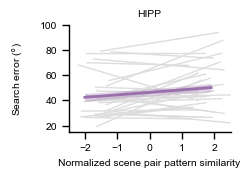

In [13]:
plot_data = ps_diff_perf_sorted.query("roi=='hipp' & sacc_type=='first'")
g = sns.lmplot(x='corr_z_norm', y='next_sacc_targ_err', hue='subj', ci=0, palette=['#dddddd'],
           legend=False, height=1.8, aspect=1.35,
           scatter=False, data=plot_data, line_kws={'lw': 1, 'zorder': -100})
x_vals = np.arange(-2, 2, .1)

fixed_intercept = mdf.fe_params['Intercept']
fixed_slope = mdf.fe_params['corr_z_norm']

y_pred = fixed_intercept + fixed_slope * x_vals
cov = mdf.cov_params()
se = np.sqrt(
    cov.loc['Intercept', 'Intercept'] +
    x_vals**2 * cov.loc['corr_z_norm', 'corr_z_norm'] +
    2 * x_vals * cov.loc['Intercept', 'corr_z_norm']
)
plt.plot(x_vals, y_pred, linewidth=2, color='#9970ab', label='Fixed effect')
plt.fill_between(x_vals, y_pred - se, y_pred + se, color='#9970ab',
                alpha=0.3, lw=0, label='95% CI')
g.axes[0][0].set(xlabel='Normalized scene pair pattern similarity',
                 ylabel='Search error ($\degree$)\n',
                 xlim=[-2.5, 2.5], ylim=[15, 100],
                 title='HIPP')
sns.despine()

plt.gcf().tight_layout()
save_fig(plt.gcf(), op.join(save_dir, 'sfig3d'))